# 구룡포시장 | 외곽형

* 자료: 공개 가능한 저장 요약값
* 관측 단위: 시장 소재 행정동, 실제 방문·구매 미확인
* 공개 범위: OD·STAY 원자료 제외

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from plotting import (FIGS, HOUR, WEEK, STAY, PURPOSE, CASE_COMPARISONS, PURPOSE_FIGURES, TIME_FIGURES,
                      plot_case_comparison, plot_purpose, plot_time_weekday)
CASE = '구룡포시장'


## 방문·체류 목적

,도착 OD,체류 STAY
귀가,11.2,50.1
업무,7.5,10.2
학업,0.4,0.2
쇼핑여가,1.9,0.7
기타,43.5,23.4
여행,35.6,15.3


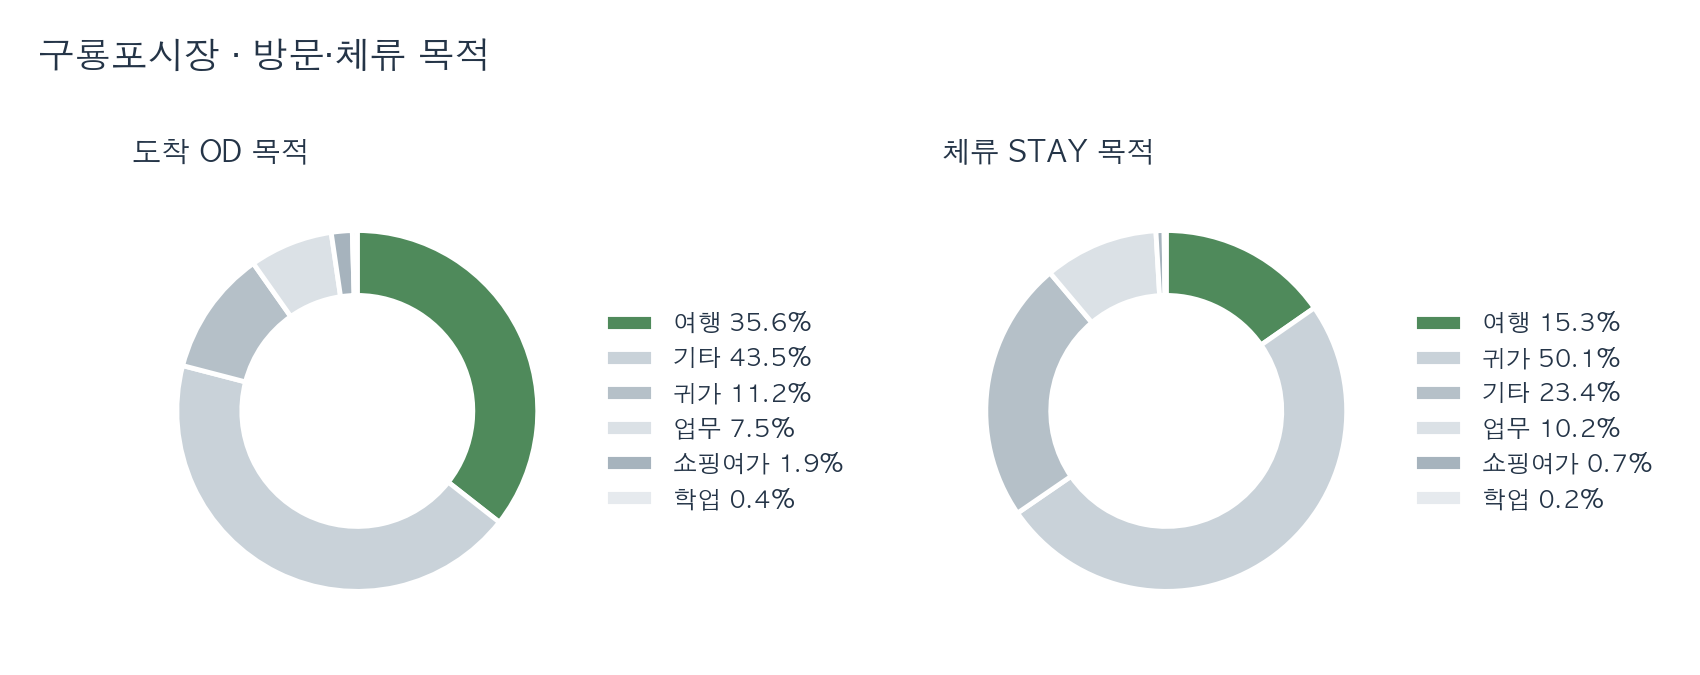

In [2]:
display((pd.DataFrame(PURPOSE[CASE]) * 100).round(1))
plot_purpose(CASE)
display(Image(filename=str(FIGS / PURPOSE_FIGURES[CASE][0])))

## 거리·접근

,지표,비교 대상,값,단위
0,쇼핑 OD 중 10km 이상 출발,구룡포,80.5,%
1,쇼핑 OD 중 10km 이상 출발,외곽형 평균,71.2,%
2,쇼핑 OD 중 10km 이상 출발,전국 평균,29.3,%
3,전 목적 OD 가중 접근시간,구룡포,82.6,분
4,전 목적 OD 가중 접근시간,외곽형 평균,63.7,분
5,전 목적 OD 가중 접근시간,전국 평균,36.1,분


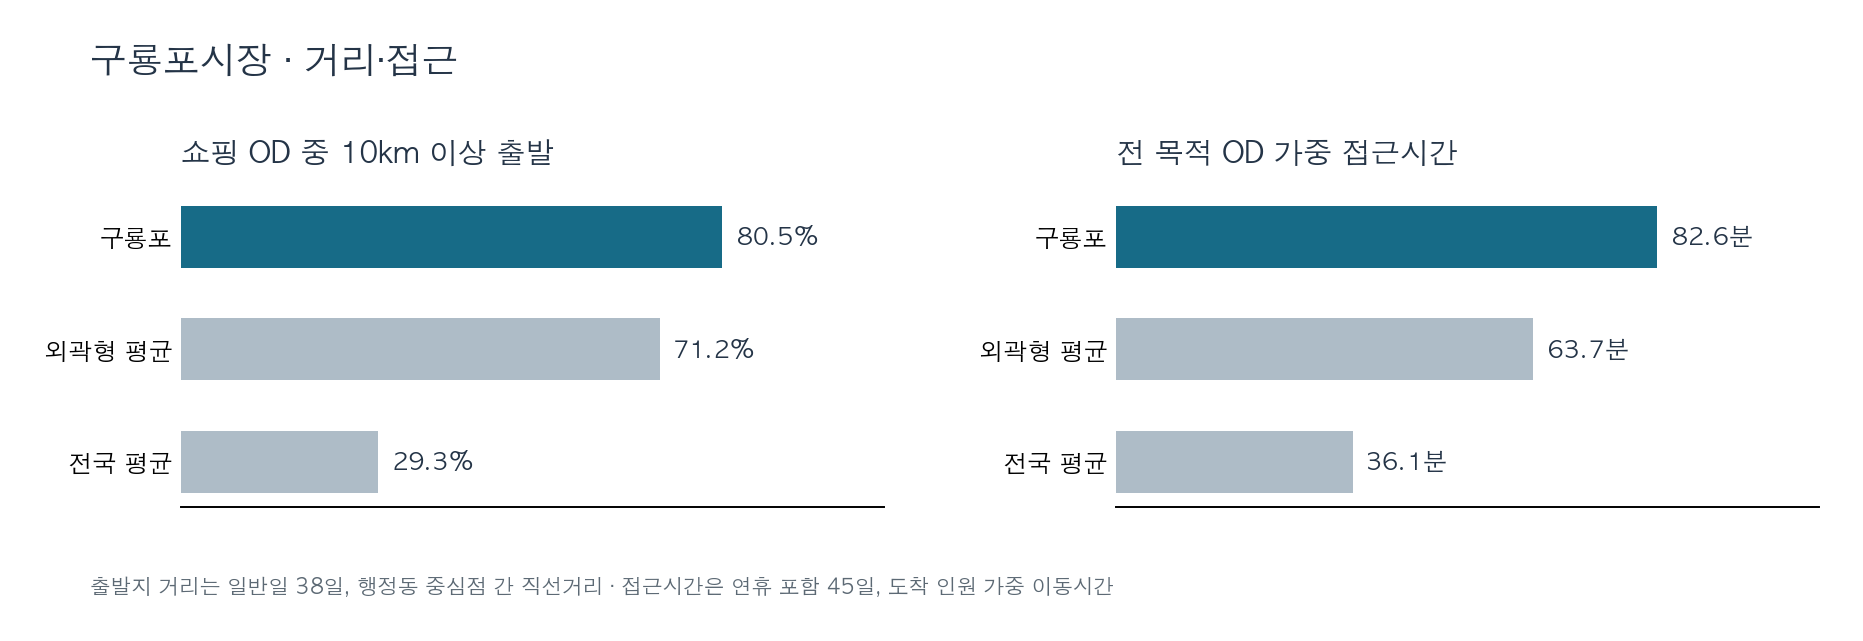

In [3]:
filename, title, panels, note = CASE_COMPARISONS[CASE]
comparison = pd.DataFrame([
    {"지표": metric, "비교 대상": name, "값": value, "단위": unit}
    for metric, names, values, unit in panels
    for name, value in zip(names, values)
])
display(comparison)
plot_case_comparison(CASE)
display(Image(filename=str(FIGS / filename)))

## 요일·시간

,measure,daytype,정점 시각,시간별 구성비 (%)
6,도착 OD 전체,주말,14,13.0
23,도착 OD 전체,평일,15,8.6
38,체류 STAY 전체,주말,14,7.1
52,체류 STAY 전체,평일,12,6.9


,measure,day_of_week,요일별 구성비 (%),observed_days
0,여행 목적 체류 STAY,0,8.7,4
1,여행 목적 체류 STAY,1,7.3,5
2,여행 목적 체류 STAY,2,8.1,6
3,여행 목적 체류 STAY,3,8.6,5
4,여행 목적 체류 STAY,4,11.8,6
5,여행 목적 체류 STAY,5,29.6,6
6,여행 목적 체류 STAY,6,26.0,6
7,도착 OD 전체,0,10.2,4
8,도착 OD 전체,1,9.1,5
9,도착 OD 전체,2,9.8,6


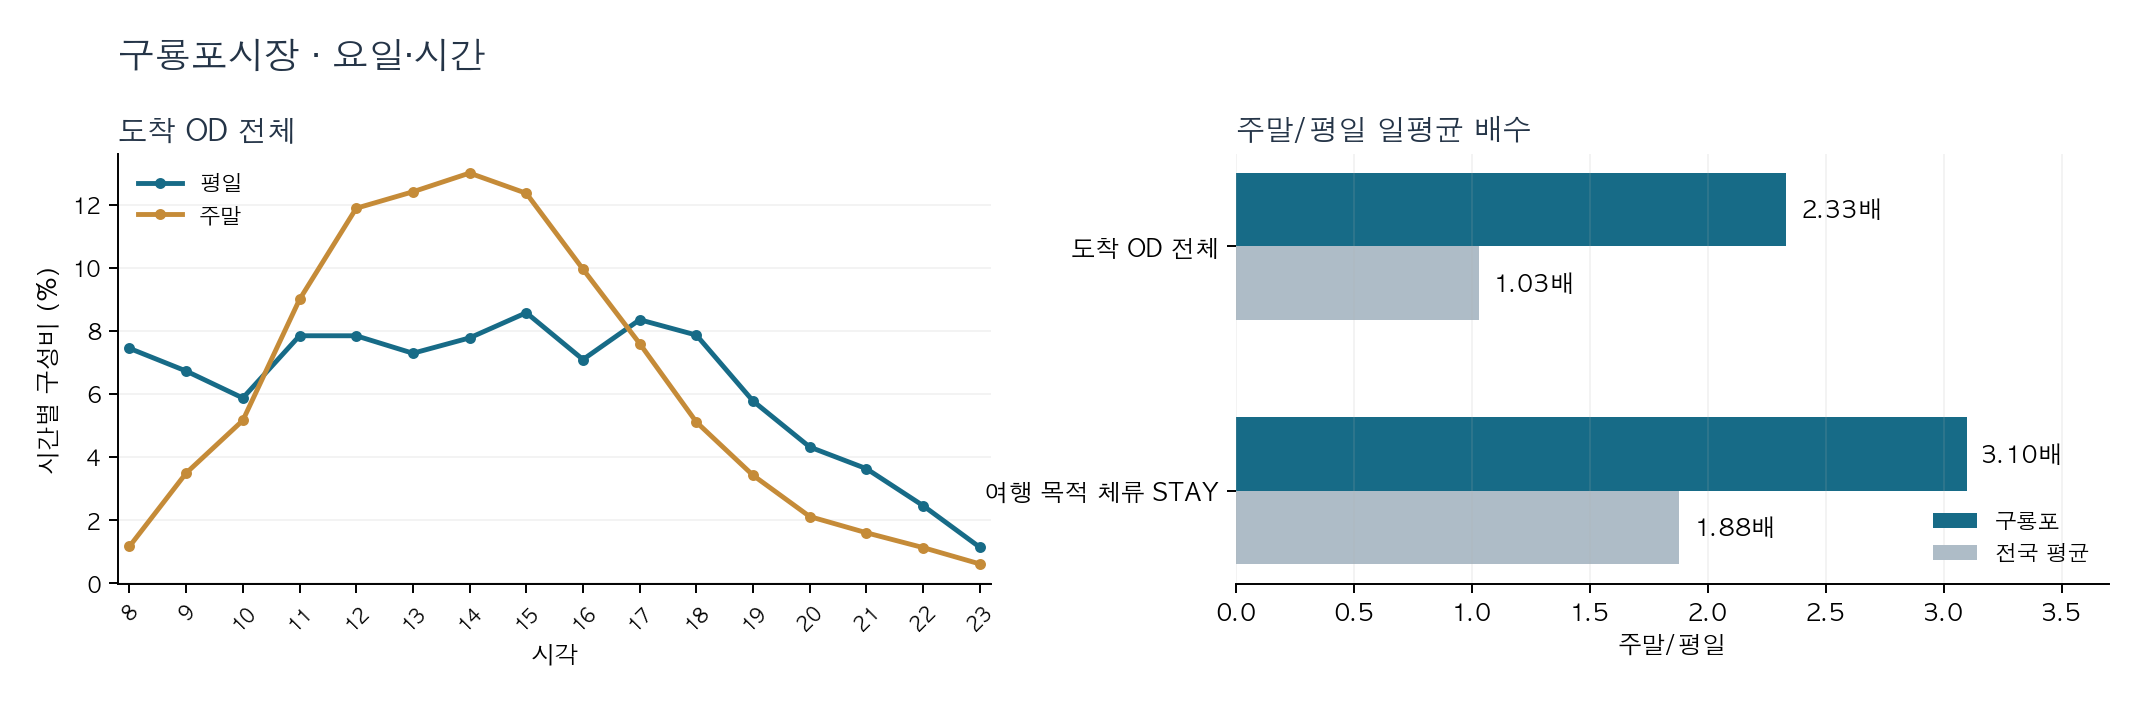

In [4]:
hourly = HOUR.loc[HOUR["case"].eq(CASE)].copy()
peaks = hourly.loc[hourly.groupby(["measure", "daytype"])["hour_share"].idxmax(),
                   ["measure", "daytype", "hour", "hour_share"]].copy()
peaks["hour_share"] = (peaks["hour_share"] * 100).round(1)
display(peaks.rename(columns={"hour":"정점 시각", "hour_share":"시간별 구성비 (%)"}))
weekday = WEEK.loc[WEEK["case"].eq(CASE)].copy()
weekday["요일별 구성비 (%)"] = weekday.groupby("measure")["daily_index"].transform(
    lambda values: values / values.sum() * 100
).round(1)
display(weekday[["measure", "day_of_week", "요일별 구성비 (%)", "observed_days"]])
plot_time_weekday(CASE)
display(Image(filename=str(FIGS / TIME_FIGURES[CASE])))

## 제안

* 방안: 비장날 주말 11~16시 영업 점포를 확인하고 여행객에게 점포·상품·접근 정보를 안내하는 시범 운영
* 판정: 영업 점포 수와 점포 매출
